# Data Cleaning

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
sns.set_style('whitegrid')

import warnings
warnings.filterwarnings('ignore')

## Loading Data

In [2]:
df=pd.read_csv('data/PRSA_data.csv')
df['date']=pd.to_datetime(df[['year','month','day','hour']])
df

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,date
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0,2010-01-01 00:00:00
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0,2010-01-01 01:00:00
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0,2010-01-01 02:00:00
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0,2010-01-01 03:00:00
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0,2010-01-01 04:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43819,43820,2014,12,31,19,8.0,-23,-2.0,1034.0,NW,231.97,0,0,2014-12-31 19:00:00
43820,43821,2014,12,31,20,10.0,-22,-3.0,1034.0,NW,237.78,0,0,2014-12-31 20:00:00
43821,43822,2014,12,31,21,10.0,-22,-3.0,1034.0,NW,242.70,0,0,2014-12-31 21:00:00
43822,43823,2014,12,31,22,8.0,-22,-4.0,1034.0,NW,246.72,0,0,2014-12-31 22:00:00


## Missing Data

In [4]:
df = df.sort_values('date').reset_index(drop=True)

n_dupes = df['date'].duplicated().sum()
print('Duplicate timestamps:', n_dupes)
df = df.drop_duplicates(subset='date').reset_index(drop=True)

print('Missing pm2.5:', df['pm2.5'].isna().sum(), f"({df['pm2.5'].isna().mean()*100:.1f}%)")
print('Missing in weather columns:')
print(df[['DEWP','TEMP','PRES','Iws','Is','Ir']].isna().sum())

Duplicate timestamps: 0
Missing pm2.5: 2067 (4.7%)
Missing in weather columns:
DEWP    0
TEMP    0
PRES    0
Iws     0
Is      0
Ir      0
dtype: int64


## Feature Engineering

### i. Calendar

In [5]:
df['hour']       = df['date'].dt.hour
df['dayofweek']  = df['date'].dt.dayofweek   # 0=Mon, 6=Sun
df['month']      = df['date'].dt.month
df['quarter']    = df['date'].dt.quarter
df['year']       = df['date'].dt.year
df['dayofyear']  = df['date'].dt.dayofyear
df['is_weekend'] = (df['dayofweek'] >= 5).astype(int)

df[['date','hour','dayofweek','month','quarter','year','dayofyear','is_weekend']].head()

,date,hour,dayofweek,month,quarter,year,dayofyear,is_weekend
0,2010-01-01 00:00:00,0,4,1,1,2010,1,0
1,2010-01-01 01:00:00,1,4,1,1,2010,1,0
2,2010-01-01 02:00:00,2,4,1,1,2010,1,0
3,2010-01-01 03:00:00,3,4,1,1,2010,1,0
4,2010-01-01 04:00:00,4,4,1,1,2010,1,0


### ii. Lag and Rolling-Mean

**Lag**
lag_1 is pollution one hour ago
lag_24 is pollution at same hour yesterday
**Rolling Mean**
roll_d is smoothed for 1 day
roll_w is smoothed for 1 week

In [6]:
df['lag_1']  = df['pm2.5'].shift(1)
df['lag_24'] = df['pm2.5'].shift(24)
df['roll_d']  = df['pm2.5'].shift(1).rolling(window=24).mean()
df['roll_w'] = df['pm2.5'].shift(1).rolling(window=168).mean()

df[['pm2.5','lag_1','lag_24','roll_d','roll_w']]

,pm2.5,lag_1,lag_24,roll_d,roll_w
0,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...
43819,8.0,10.0,35.0,12.416667,121.476190
43820,10.0,8.0,26.0,11.291667,121.404762
43821,10.0,10.0,20.0,10.625000,121.327381
43822,8.0,10.0,8.0,10.208333,121.291667


###  iii. Wind direction
as cdwd is categorical it is divided into several binary columns

In [7]:
df = pd.get_dummies(df, columns=['cbwd'], prefix='wind', drop_first=True)
wind_cols = [c for c in df.columns if c.startswith('wind_')]
df[wind_cols] = df[wind_cols].astype(int)
print('Wind indicator columns:', wind_cols)
df[wind_cols].head()

Wind indicator columns: ['wind_NW', 'wind_SE', 'wind_cv']


,wind_NW,wind_SE,wind_cv
0,1,0,0
1,1,0,0
2,1,0,0
3,1,0,0
4,1,0,0


### iv. Dropping NaN Rows

In [8]:
before = len(df)
df = df.dropna(subset=['pm2.5','lag_1','lag_24','roll_d','roll_w']).reset_index(drop=True) # as seen before starting rows cant have lag or rolling means
after = len(df)
print(f'Dropped {before - after:,} rows (missing target / lag warmup)')
print(f'Final shape: {df.shape}')
print('Any remaining NaNs:', int(df.isna().sum().sum()))

Dropped 20,910 rows (missing target / lag warmup)
Final shape: (22914, 24)
Any remaining NaNs: 0


In [9]:
df

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,Iws,...,quarter,dayofyear,is_weekend,lag_1,lag_24,roll_d,roll_w,wind_NW,wind_SE,wind_cv
0,193,2010,1,9,0,165.0,-17,-13.0,1027.0,0.89,...,1,9,1,169.0,210.0,176.208333,85.744048,0,0,1
1,194,2010,1,9,1,159.0,-17,-13.0,1027.0,3.13,...,1,9,1,165.0,195.0,174.333333,85.958333,1,0,0
2,195,2010,1,9,2,167.0,-17,-14.0,1027.0,4.92,...,1,9,1,159.0,275.0,172.833333,86.023810,1,0,0
3,196,2010,1,9,3,196.0,-17,-15.0,1027.0,8.05,...,1,9,1,167.0,164.0,168.333333,86.071429,1,0,0
4,197,2010,1,9,4,169.0,-17,-13.0,1027.0,9.84,...,1,9,1,196.0,110.0,169.666667,86.160714,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22909,43820,2014,12,31,19,8.0,-23,-2.0,1034.0,231.97,...,4,365,0,10.0,35.0,12.416667,121.476190,1,0,0
22910,43821,2014,12,31,20,10.0,-22,-3.0,1034.0,237.78,...,4,365,0,8.0,26.0,11.291667,121.404762,1,0,0
22911,43822,2014,12,31,21,10.0,-22,-3.0,1034.0,242.70,...,4,365,0,10.0,20.0,10.625000,121.327381,1,0,0
22912,43823,2014,12,31,22,8.0,-22,-4.0,1034.0,246.72,...,4,365,0,10.0,8.0,10.208333,121.291667,1,0,0


### lag - target relation

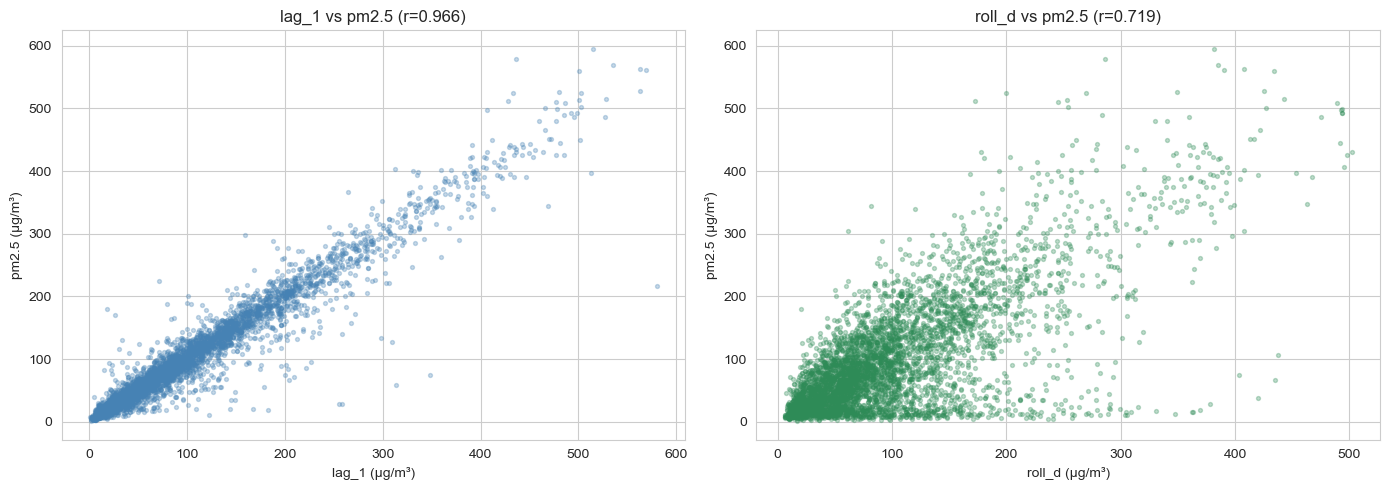

In [10]:
sample = df.sample(5000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(sample['lag_1'], sample['pm2.5'], alpha=0.3, s=8, color='steelblue')
axes[0].set_xlabel('lag_1 (µg/m³)'); axes[0].set_ylabel('pm2.5 (µg/m³)')
axes[0].set_title(f"lag_1 vs pm2.5 (r={df[['lag_1','pm2.5']].corr().iloc[0,1]:.3f})")
axes[1].scatter(sample['roll_d'], sample['pm2.5'], alpha=0.3, s=8, color='seagreen')
axes[1].set_xlabel('roll_d (µg/m³)'); axes[1].set_ylabel('pm2.5 (µg/m³)')
axes[1].set_title(f"roll_d vs pm2.5 (r={df[['roll_d','pm2.5']].corr().iloc[0,1]:.3f})")
plt.tight_layout(); plt.show()

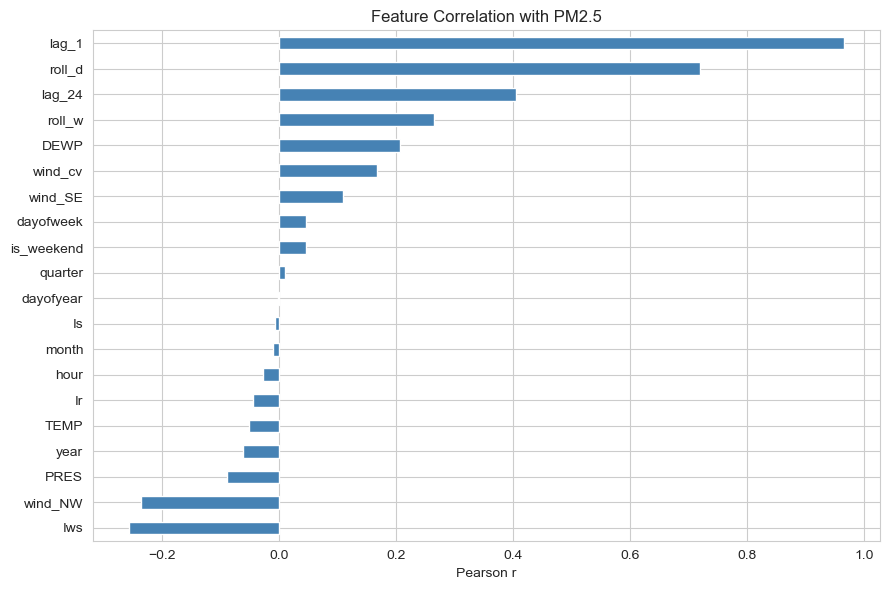

In [11]:
feature_cols = ['hour','dayofweek','month','quarter','year','dayofyear','is_weekend',
                'DEWP','TEMP','PRES','Iws','Is','Ir',
                'lag_1','lag_24','roll_d','roll_w'] + wind_cols
corr_t = df[feature_cols + ['pm2.5']].corr()['pm2.5'].drop('pm2.5').sort_values()

plt.figure(figsize=(9, 6))
corr_t.plot(kind='barh', color='steelblue')
plt.title('Feature Correlation with PM2.5'); plt.xlabel('Pearson r')
plt.tight_layout(); plt.show()

## Save Cleaned CSV

In [11]:
df.to_csv('data/clean_aqi_features.csv', index=False)
print(f'Saved {len(df):,} rows × {df.shape[1]} cols to {'data/clean_aqi_features.csv'}')
df.head()

Saved 22,914 rows × 24 cols to data/clean_aqi_features.csv


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,Iws,...,quarter,dayofyear,is_weekend,lag_1,lag_24,roll_d,roll_w,wind_NW,wind_SE,wind_cv
0,193,2010,1,9,0,165.0,-17,-13.0,1027.0,0.89,...,1,9,1,169.0,210.0,176.208333,85.744048,0,0,1
1,194,2010,1,9,1,159.0,-17,-13.0,1027.0,3.13,...,1,9,1,165.0,195.0,174.333333,85.958333,1,0,0
2,195,2010,1,9,2,167.0,-17,-14.0,1027.0,4.92,...,1,9,1,159.0,275.0,172.833333,86.023810,1,0,0
3,196,2010,1,9,3,196.0,-17,-15.0,1027.0,8.05,...,1,9,1,167.0,164.0,168.333333,86.071429,1,0,0
4,197,2010,1,9,4,169.0,-17,-13.0,1027.0,9.84,...,1,9,1,196.0,110.0,169.666667,86.160714,1,0,0
